# Libraries 

In [1]:
import glob  # use to process jpg files
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [4]:
from PIL import Image

# 1. Data collection

In [5]:
no_smile = glob.glob("data/non_smile/*.jpg")

In [6]:
type(no_smile)

list

In [7]:
no_smile[0]

'data/non_smile\\Aaron_Eckhart_0001.jpg'

In [8]:
smile = glob.glob("data/smile/*.jpg")
test = glob.glob("data/test/*.jpg")

In [9]:
len(smile), len(no_smile), len(test)

(600, 603, 12030)

# 2. Data Cleaning

In [10]:
img = Image.open(smile[18])

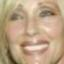

In [11]:
img

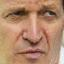

In [12]:
Image.open(no_smile[40])

In [13]:
img = img.convert('L')

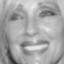

In [14]:
img

In [15]:
pixel_array = np.array(img)

In [16]:
pixel_array

array([[203, 199, 192, ..., 195, 197, 195],
       [201, 198, 188, ..., 195, 198, 199],
       [198, 195, 184, ..., 195, 200, 202],
       ...,
       [152, 140, 124, ..., 173, 163, 163],
       [160, 149, 134, ..., 171, 163, 165],
       [167, 157, 142, ..., 166, 163, 165]], shape=(64, 64), dtype=uint8)

In [17]:
type(pixel_array)  #2D array

numpy.ndarray

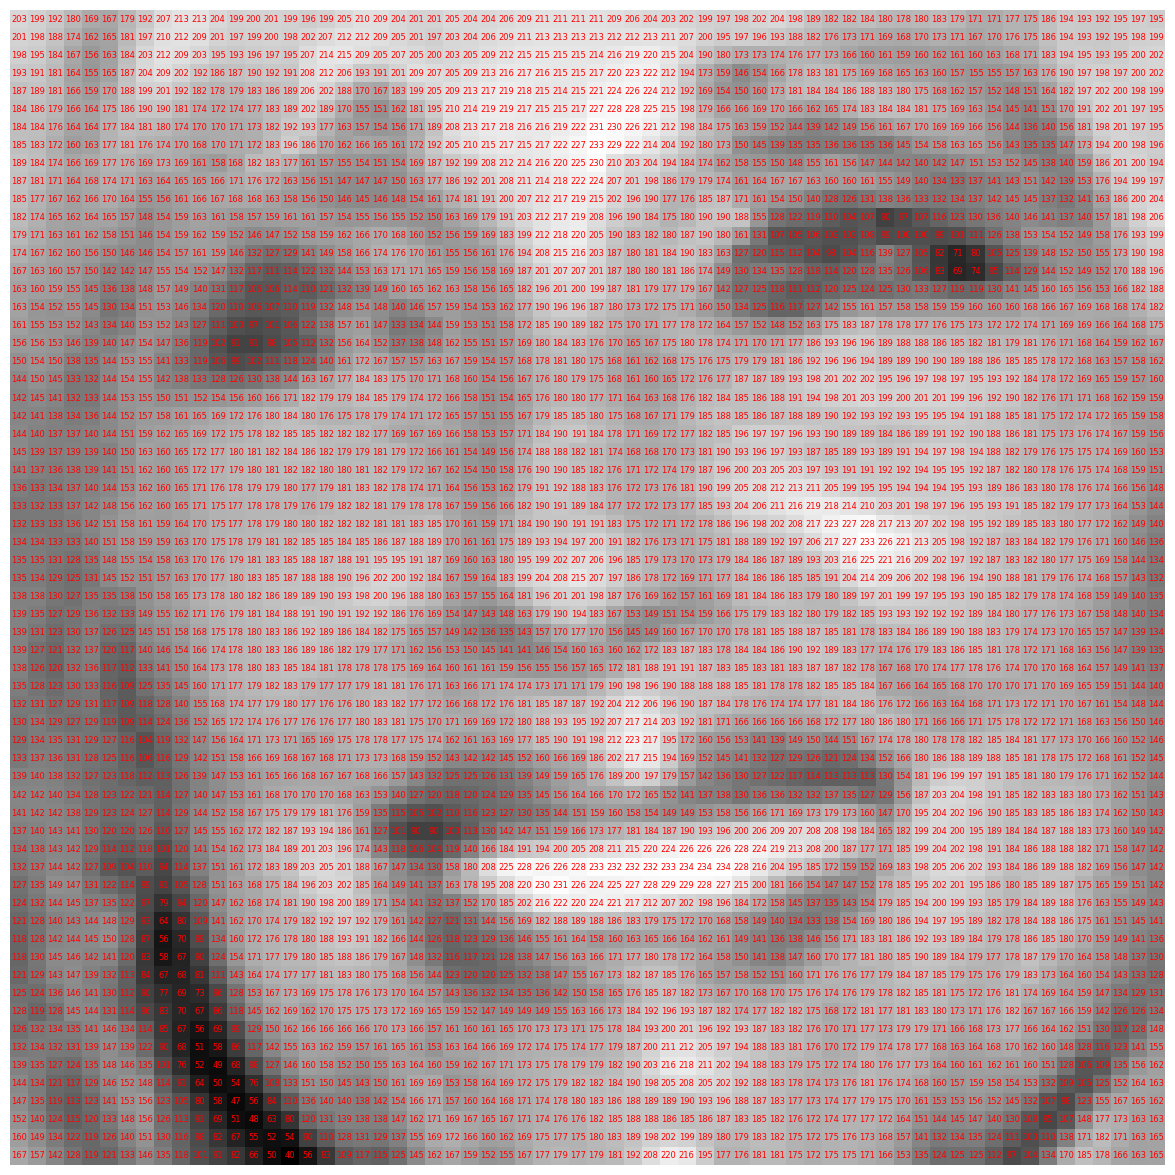

In [18]:
plt.figure(figsize=(15,15))
plt.imshow(pixel_array, cmap="gray", interpolation="nearest")

#Show pixel values ovelaid on image
for i in range(64):
    for j in range(64):
        plt.text(j, i, pixel_array[i,j], ha="center", va="center", fontsize=6, color="red")

plt.axis("off")
plt.show()

In [19]:
data = []
labels = []

In [20]:
# no_smile images
for image in no_smile:
    img = Image.open(image)
    img = img.convert('L')
    img = np.array(img).flatten() ## 3D array cant be Standardized, 
    #so we going to convert into 2D 
    data.append(img)
    labels.append(0)

In [21]:
len(data), len(labels)

(603, 603)

In [22]:
# smile images
for image in smile:
    img = Image.open(image)
    img = img.convert('L')
    img = np.array(img).flatten()
    data.append(img)
    labels.append(1)

In [23]:
len(data), len(labels)

(1203, 1203)

In [24]:
type(data)

list

In [25]:
X = np.array(data)

In [26]:
y = np.array(labels)

# Model development

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    random_state=42, shuffle=True)

In [28]:
type(X_train)

numpy.ndarray

In [29]:
X_train.shape

(962, 4096)

In [30]:
X_train[0]

array([ 97, 112, 127, ...,  12,  12,  13], shape=(4096,), dtype=uint8)

In [31]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [32]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
X_train_scaled[0]

array([-0.02538072,  0.19720776,  0.40115046, ..., -1.43250336,
       -1.41042084, -1.37429772], shape=(4096,))

In [34]:
model = LogisticRegression()

In [35]:
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [36]:
y_pred = model.predict(X_test_scaled)

In [37]:
y_pred ## 1 - smile , 0 - no_smile

array([1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1])

In [38]:
model.predict_proba(X_test_scaled)

array([[4.72060375e-06, 9.99995279e-01],
       [2.48073568e-01, 7.51926432e-01],
       [9.90126214e-01, 9.87378617e-03],
       [2.16298091e-11, 1.00000000e+00],
       [1.00000000e+00, 4.81260384e-12],
       [9.95139836e-01, 4.86016421e-03],
       [2.40434177e-07, 9.99999760e-01],
       [9.99996392e-01, 3.60849294e-06],
       [3.24469696e-09, 9.99999997e-01],
       [1.55912386e-04, 9.99844088e-01],
       [6.16235485e-03, 9.93837645e-01],
       [2.52692183e-08, 9.99999975e-01],
       [9.99999935e-01, 6.50809143e-08],
       [9.91609270e-01, 8.39072992e-03],
       [1.00000000e+00, 4.31811185e-10],
       [9.99999947e-01, 5.26841185e-08],
       [2.86972731e-02, 9.71302727e-01],
       [9.99924908e-01, 7.50923591e-05],
       [1.25304226e-08, 9.99999987e-01],
       [9.99995244e-01, 4.75591766e-06],
       [2.26290275e-09, 9.99999998e-01],
       [1.11325418e-02, 9.88867458e-01],
       [9.96691628e-01, 3.30837195e-03],
       [2.73834270e-08, 9.99999973e-01],
       [9.996634

In [39]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Model Accuracy: 0.8963
Confusion Matrix:
 [[115  11]
 [ 14 101]]
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.91      0.90       126
           1       0.90      0.88      0.89       115

    accuracy                           0.90       241
   macro avg       0.90      0.90      0.90       241
weighted avg       0.90      0.90      0.90       241



# Hyperparameter Tuning

In [40]:
param = { 'penalty' : ['l1', 'l2', 'elasticnet'],
           'C' : [1,10,100,0.1,0.01]
        }

In [41]:
from sklearn.model_selection import GridSearchCV

In [42]:
log_reg = LogisticRegression()

In [43]:
grid_search = GridSearchCV(log_reg, param, n_jobs=-1, cv=5, scoring='accuracy')

In [44]:
grid_search.fit(X_train_scaled, y_train)

c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
50 fits failed out of a total of 75.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
25 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sk

,estimator,LogisticRegression()
,param_grid,"{'C': [1, 10, ...], 'penalty': ['l1', 'l2', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [45]:
grid_search.best_params_

{'C': 0.01, 'penalty': 'l2'}

In [46]:
grid_search.best_score_

np.float64(0.8804134283246977)

### Test with new image
- gray scale
- numpy array
- flatten
- scaling

#### Test with smile data

In [77]:
image = Image.open('my_samples/thala_smiley.jpg')

In [78]:
image = image.resize((64,64))

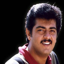

In [79]:
image

In [80]:
image = image.convert('L')

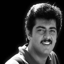

In [81]:
image

In [82]:
image_array = np.array(image).flatten()

In [83]:
image_array.shape

(4096,)

In [84]:
scaled_array = scaler.transform(image_array.reshape(1,-1))

In [85]:
model.predict(scaled_array)

array([1])

#### Test with no_smile data

In [68]:
image = Image.open('my_samples/thala_no_smiley.jpg')

In [69]:
image = image.resize((64,64))

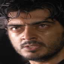

In [70]:
image

In [71]:
image = image.convert('L')

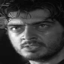

In [72]:
image

In [73]:
image_array = np.array(image).flatten()

In [74]:
image_array.shape

(4096,)

In [75]:
scaled_array = scaler.transform(image_array.reshape(1,-1))

In [76]:
model.predict(scaled_array)

array([0])

# Save the model

In [65]:
import pickle

In [66]:
pickle.dump(model, open('my_model.pkl', 'wb'))

In [67]:
pickle.dump(scaler, open('my_scaler.pkl', 'wb'))